# Calculate weights for drought monitor using PCA

* **Products used:** 
[ls8_sr](https://explorer.digitalearth.africa/ls8_sr)

## Background

This is a weight generation notebook for calculating weights for the DE Africa Drought Monitor.

## Description
This notebook calculates pixel-scale weights from principal component analysis for 25 years of reference data from 2000-2025.



1. Load and harmonise Landsat-7, 8 and 9 data from 2000 onwards to produce a 25-year NDVI dataset.
2. Load CHIRPS monthly rainfall from 2000-2025 and produce SPI-3.
3. Load Soil Moisture from CPC for 2000-2025.
4. Load reference ET for 2000-2025.
5. Normalise data by calculating percentiles.
6. Conduct Principal Component Analysis  to determine variable weights.
7. Test sensitivity to reference period using bootstrap (leave one year out) test.


***

## Getting started

Provide any particular instructions that the user might need, e.g. To run this analysis, run all the cells in the notebook, starting with the "Load packages" cell. 

### Load packages
Import Python packages that are used for the analysis.

Use standard import commands; some are shown below. 
Begin with any `iPython` magic commands, followed by standard Python packages, then any additional functionality you need from the `Tools` package.

In [53]:
%matplotlib inline

import datacube
import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import planetary_computer
import pystac_client
import matplotlib.pyplot as plt
import scipy.stats as stats
import requests
import calendar

from scipy.stats import gamma, norm
from tqdm.auto import tqdm
from odc.geo import Geometry, CRS
from dask.diagnostics import ProgressBar
from odc.geo.xr import xr_reproject
from odc.ui import with_ui_cbk
from deafrica_tools.datahandling import load_ard
from deafrica_tools.spatial import xr_rasterize
from scipy import stats
from collections import defaultdict

### Connect to the datacube

Connect to the datacube so we can access DE Africa data.
The `app` parameter is a unique name for the analysis which is based on the notebook file name.

In [2]:
dc = datacube.Datacube(app='DEA_notebooks_template')

## Load Africa admin boundaries and enable country selection

In [3]:
# Query geoBoundaries global metadata
url = "https://www.geoboundaries.org/api/current/gbOpen/ALL/ADM0/"
data = requests.get(url).json()

# Parse into a DataFrame
df = pd.DataFrame(data)

# Filter by continent (e.g., Africa)
africa_countries = df[df["Continent"] == "Africa"]
africa_iso3 = africa_countries["boundaryISO"].unique().tolist()

print(f"Total geoBoundaries Africa codes: {len(africa_iso3)}")
print(africa_iso3)

Total geoBoundaries Africa codes: 57
['AGO', 'BDI', 'BEN', 'BFA', 'BWA', 'CAF', 'CIV', 'CMR', 'COD', 'COG', 'COM', 'CPV', 'DJI', 'DZA', 'EGY', 'ERI', 'ETH', 'GAB', 'GHA', 'GIN', 'GMB', 'GNB', 'GNQ', 'KEN', 'LBR', 'LBY', 'LSO', 'MAR', 'MDG', 'MLI', 'MOZ', 'MRT', 'MUS', 'MWI', 'MYT', 'NAM', 'NER', 'NGA', 'REU', 'RWA', 'SDN', 'SEN', 'SHN', 'SLE', 'SOM', 'SSD', 'STP', 'SWZ', 'SYC', 'TCD', 'TGO', 'TUN', 'TZA', 'UGA', 'ZAF', 'ZMB', 'ZWE']


### Select country

Select African country for testing from list of country codes above.

In [4]:
countries = gpd.read_file("/home/jovyan/dev/deafrica-sandbox-notebooks/Supplementary_data/Rainfall_anomaly_CHIRPS/african_countries.geojson")

print(np.unique(countries.COUNTRY))

['Algeria' 'Angola' 'Benin' 'Botswana' 'Burkina Faso' 'Burundi' 'Cameroon'
 'Cape Verde' 'Central African Republic' 'Chad' 'Comoros'
 'Congo-Brazzaville' 'Cote d`Ivoire' 'Democratic Republic of Congo'
 'Djibouti' 'Egypt' 'Equatorial Guinea' 'Eritrea' 'Ethiopia' 'Gabon'
 'Gambia' 'Ghana' 'Guinea' 'Guinea-Bissau' 'Kenya' 'Lesotho' 'Liberia'
 'Libya' 'Madagascar' 'Malawi' 'Mali' 'Mauritania' 'Morocco' 'Mozambique'
 'Namibia' 'Niger' 'Nigeria' 'Rwanda' 'Sao Tome and Principe' 'Senegal'
 'Sierra Leone' 'Somalia' 'South Africa' 'Sudan' 'Swaziland' 'Tanzania'
 'Togo' 'Tunisia' 'Uganda' 'Western Sahara' 'Zambia' 'Zimbabwe']


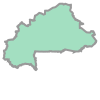

In [5]:
country = 'Burkina Faso'

gdf_sel = countries[countries['COUNTRY'] == country]

idx = gdf_sel.index[0]

geom = Geometry(geom=countries.iloc[idx].geometry, crs=countries.crs)

geom

## Set a bounding box and time period



In [6]:
# Set a bounding box
# [xmin, ymin, xmax, ymax] in latitude and longitude
bbox = [gdf_sel.total_bounds[0], gdf_sel.total_bounds[1], gdf_sel.total_bounds[2], gdf_sel.total_bounds[3]]

# Set a start and end date
start_date = "2000-01-01"
end_date = "2025-12-31"

## Set CRS and resolution

In [7]:
crs = "EPSG:4326"
resolution = (-0.05, 0.05)

## Load Landsat-7

In [8]:
ds_ls7 = load_ard(dc=dc,
              products=["ls7_sr"],
              measurements=['red', 'nir'],
              output_crs=crs,
              y=(gdf_sel.total_bounds[1], gdf_sel.total_bounds[3]),
              x=(gdf_sel.total_bounds[0], gdf_sel.total_bounds[2]),
              time=(start_date, end_date),
              resolution=(-0.05, 0.05),
              group_by="solar_day",
              dask_chunks={'time':-1}
             )

ds_ls7

Using pixel quality parameters for USGS Collection 2
Finding datasets
    ls7_sr
Applying pixel quality/cloud mask
Re-scaling Landsat C2 data
Returning 2908 time steps as a dask array


/opt/venv/lib/python3.12/site-packages/deafrica_tools/datahandling.py:565: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  ds = xr.merge([ds_data, ds_masks])


<xarray.Dataset> Size: 424MB
Dimensions:      (time: 2908, latitude: 114, longitude: 160)
Coordinates:
  * time         (time) datetime64[ns] 23kB 2000-01-01T10:18:04.454034 ... 20...
  * latitude     (latitude) float64 912B 15.08 15.03 14.98 ... 9.525 9.475 9.425
  * longitude    (longitude) float64 1kB -5.525 -5.475 -5.425 ... 2.375 2.425
    spatial_ref  int32 4B 4326
Data variables:
    red          (time, latitude, longitude) float32 212MB dask.array<chunksize=(2908, 114, 160), meta=np.ndarray>
    nir          (time, latitude, longitude) float32 212MB dask.array<chunksize=(2908, 114, 160), meta=np.ndarray>
Attributes:
    crs:           EPSG:4326
    grid_mapping:  spatial_ref

### Compute Landsat-7 NDVI and conduct linear transformation

In [9]:
ds_ls7_ndvi = ((((ds_ls7.nir - ds_ls7.red) / (ds_ls7.nir + ds_ls7.red)) + 0.015) / 0.988).to_dataset(name='NDVI')

## Load Landsat-8

In [10]:
ds_ls8 = load_ard(dc=dc,
              products=["ls8_sr"],
              measurements=['red', 'nir'],
              output_crs=crs,
              y=(gdf_sel.total_bounds[1], gdf_sel.total_bounds[3]),
              x=(gdf_sel.total_bounds[0], gdf_sel.total_bounds[2]),
              time=(start_date, end_date),
              resolution=(-0.05, 0.05),
              group_by="solar_day",
              dask_chunks={'time':5}
             )

ds_ls8

Using pixel quality parameters for USGS Collection 2
Finding datasets
    ls8_sr
Applying pixel quality/cloud mask
Re-scaling Landsat C2 data
Returning 2012 time steps as a dask array


/opt/venv/lib/python3.12/site-packages/deafrica_tools/datahandling.py:565: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  ds = xr.merge([ds_data, ds_masks])


<xarray.Dataset> Size: 294MB
Dimensions:      (time: 2012, latitude: 114, longitude: 160)
Coordinates:
  * time         (time) datetime64[ns] 16kB 2013-03-22T10:30:25.859518 ... 20...
  * latitude     (latitude) float64 912B 15.08 15.03 14.98 ... 9.525 9.475 9.425
  * longitude    (longitude) float64 1kB -5.525 -5.475 -5.425 ... 2.375 2.425
    spatial_ref  int32 4B 4326
Data variables:
    red          (time, latitude, longitude) float32 147MB dask.array<chunksize=(5, 114, 160), meta=np.ndarray>
    nir          (time, latitude, longitude) float32 147MB dask.array<chunksize=(5, 114, 160), meta=np.ndarray>
Attributes:
    crs:           EPSG:4326
    grid_mapping:  spatial_ref

### Compute Landsat-8 NDVI

In [11]:
ds_ls8_ndvi = ((ds_ls8.nir - ds_ls8.red) / (ds_ls8.nir + ds_ls8.red)).to_dataset(name='NDVI')

## Load Landsat-9

In [12]:
ds_ls9 = load_ard(dc=dc,
              products=["ls9_sr"],
              measurements=['red', 'nir'],
              output_crs=crs,
              y=(gdf_sel.total_bounds[1], gdf_sel.total_bounds[3]),
              x=(gdf_sel.total_bounds[0], gdf_sel.total_bounds[2]),
              time=(start_date, end_date),
              resolution=(-0.05, 0.05),
              group_by="solar_day",
              dask_chunks={'time':5}
             )

ds_ls9

Using pixel quality parameters for USGS Collection 2
Finding datasets
    ls9_sr
Applying pixel quality/cloud mask
Re-scaling Landsat C2 data
Returning 651 time steps as a dask array


/opt/venv/lib/python3.12/site-packages/deafrica_tools/datahandling.py:565: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  ds = xr.merge([ds_data, ds_masks])


<xarray.Dataset> Size: 95MB
Dimensions:      (time: 651, latitude: 114, longitude: 160)
Coordinates:
  * time         (time) datetime64[ns] 5kB 2021-11-01T10:25:20.524273 ... 202...
  * latitude     (latitude) float64 912B 15.08 15.03 14.98 ... 9.525 9.475 9.425
  * longitude    (longitude) float64 1kB -5.525 -5.475 -5.425 ... 2.375 2.425
    spatial_ref  int32 4B 4326
Data variables:
    red          (time, latitude, longitude) float32 47MB dask.array<chunksize=(5, 114, 160), meta=np.ndarray>
    nir          (time, latitude, longitude) float32 47MB dask.array<chunksize=(5, 114, 160), meta=np.ndarray>
Attributes:
    crs:           EPSG:4326
    grid_mapping:  spatial_ref

### Compute Landsat-9 NDVI

In [13]:
ds_ls9_ndvi = ((ds_ls9.nir - ds_ls9.red) / (ds_ls9.nir + ds_ls9.red)).to_dataset(name='NDVI')

## Merge and resample NDVI to monthly

Takes about 100 minutes for a small country.

In [14]:
with ProgressBar():
    ds_ndvi_merge = (
        xr.concat([ds_ls7_ndvi, ds_ls8_ndvi, ds_ls9_ndvi], dim="time")
        .sortby("time")
        .resample(time="1ME")
        .mean()
        .compute()
    )

ds_ndvi_merge

[                                        ] | 0% Completed | 15.39 sms

/opt/venv/lib/python3.12/site-packages/rasterio/warp.py:385: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(
/opt/venv/lib/python3.12/site-packages/rasterio/warp.py:385: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


[########################################] | 100% Completed | 81m 5s


<xarray.Dataset> Size: 23MB
Dimensions:      (time: 312, latitude: 114, longitude: 160)
Coordinates:
  * time         (time) datetime64[ns] 2kB 2000-01-31 2000-02-29 ... 2025-12-31
  * latitude     (latitude) float64 912B 15.08 15.03 14.98 ... 9.525 9.475 9.425
  * longitude    (longitude) float64 1kB -5.525 -5.475 -5.425 ... 2.375 2.425
    spatial_ref  int32 4B 4326
Data variables:
    NDVI         (time, latitude, longitude) float32 23MB nan nan ... 0.4684

## Load CHIRPS

In [15]:
query = {'time': (start_date, end_date),
         'output_crs': crs,
         'resolution': resolution,
         'y':(gdf_sel.total_bounds[1], gdf_sel.total_bounds[3]),
         'x':(gdf_sel.total_bounds[0], gdf_sel.total_bounds[2]),
         'measurements': ['rainfall']
        }

ds_rf = dc.load(product='rainfall_chirps_monthly', progress_cbk=with_ui_cbk(), **query)
ds_rf

<xarray.Dataset> Size: 22MB
Dimensions:      (time: 308, latitude: 114, longitude: 160)
Coordinates:
  * time         (time) datetime64[ns] 2kB 2000-01-16T11:59:59.500000 ... 202...
  * latitude     (latitude) float64 912B 15.08 15.03 14.98 ... 9.525 9.475 9.425
  * longitude    (longitude) float64 1kB -5.525 -5.475 -5.425 ... 2.375 2.425
    spatial_ref  int32 4B 4326
Data variables:
    rainfall     (time, latitude, longitude) float32 22MB 0.03183 ... 4.019
Attributes:
    crs:           EPSG:4326
    grid_mapping:  spatial_ref

## Calculate SPI-3

In [16]:
# 1. 3-Month Accumulated Rainfall
rainfall_3m = ds_rf["rainfall"].rolling(time=3, min_periods=3).sum()

# Robust SciPy SPI-1D fitting function
def _scipy_spi_1d(arr):
  if np.isnan(arr).all():
    return arr

  nan_mask = np.isnan(arr)
  valid_p = arr[~nan_mask]

  if len(valid_p) < 3:
    return np.full_like(arr, np.nan)

  # Treat all values <= 0 as zero rainfall (handles floating-point precision like -1e-12)
  zeros_mask = valid_p <= 0
  q = np.sum(zeros_mask) / len(valid_p)
  non_zeros = valid_p[~zeros_mask]

  spi_valid = np.full_like(valid_p, np.nan)

  # Must have strictly positive values AND non-zero variance to fit Gamma
  if len(non_zeros) >= 3 and np.std(non_zeros) > 0:
    try:
      # Fit Gamma distribution (floc=0 fixes location parameter to 0)
      shape, loc, scale = gamma.fit(non_zeros, floc=0)
      g_x = gamma.cdf(non_zeros, shape, loc=loc, scale=scale)

      # Cumulative probability H(x) = q + (1 - q) * G(x)
      h_x = np.clip(q + (1 - q) * g_x, 1e-6, 1 - 1e-6)

      # Standard Normal Transformation
      spi_valid[~zeros_mask] = norm.ppf(h_x)

      if np.any(zeros_mask):
        spi_valid[zeros_mask] = norm.ppf(np.clip(q, 1e-6, 1 - 1e-6))
    except Exception:
      # Fallback to NaN if numerical optimization fails to converge
      pass
  elif len(non_zeros) == 0:
    # If every value in the time series is 0
    spi_valid[:] = norm.ppf(np.clip(q, 1e-6, 1 - 1e-6))

  spi_full = np.full_like(arr, np.nan)
  spi_full[~nan_mask] = spi_valid
  return spi_full


# Apply vectorized across time dimension per month group
spi_3_da = (
    rainfall_3m.groupby("time.month")
    .map(
        lambda da: xr.apply_ufunc(
            _scipy_spi_1d,
            da,
            input_core_dims=[["time"]],
            output_core_dims=[["time"]],
            vectorize=True,
            dask="parallelized",
            output_dtypes=[float],
        )
    )
    .sortby("time")
)

# Save directly into fresh Dataset
ds_spi3 = xr.Dataset(data_vars={"SPI_3": spi_3_da}, coords=ds_rf.coords)

ds_spi3['time'] = ds_spi3['time'].values.astype('datetime64[M]')

ds_spi3

<xarray.Dataset> Size: 45MB
Dimensions:      (time: 308, latitude: 114, longitude: 160)
Coordinates:
  * time         (time) datetime64[s] 2kB 2000-01-01 2000-02-01 ... 2025-12-01
  * latitude     (latitude) float64 912B 15.08 15.03 14.98 ... 9.525 9.475 9.425
  * longitude    (longitude) float64 1kB -5.525 -5.475 -5.425 ... 2.375 2.425
    spatial_ref  int32 4B 4326
Data variables:
    SPI_3        (time, latitude, longitude) float64 45MB nan nan ... 0.3394

# Load Soil Moisture

In [20]:
opendap_url = (
    "https://psl.noaa.gov/thredds/dodsC/Datasets/cpcsoil/soilw.mon.mean.v2.nc"
)

ds = xr.open_dataset(opendap_url)

min_lon, min_lat, max_lon, max_lat = gdf_sel.total_bounds
time_slice = slice("2000-01-01", "2025-12-31")
lat_slice = slice(max_lat, min_lat)  # Descending (North -> South)

# Slice in native [0, 360] BEFORE sorting so OPeNDAP only receives contiguous index ranges
if min_lon < 0 and max_lon > 0:
    # Case A: Country crosses Prime Meridian (e.g., Burkina Faso: -5.52 to 2.41)
    west_part = ds["soilw"].sel(
        time=time_slice, lat=lat_slice, lon=slice(min_lon % 360, 360)
    )
    east_part = ds["soilw"].sel(
        time=time_slice, lat=lat_slice, lon=slice(0, max_lon)
    )
    ds_sm = xr.concat([west_part, east_part], dim="lon").load()
else:
    # Case B: Country is entirely West (Senegal) or entirely East (Zambia)
    ds_sm = (
        ds["soilw"]
        .sel(
            time=time_slice,
            lat=lat_slice,
            lon=slice(min_lon % 360, max_lon % 360),
        )
        .load()
    )

# Now that the small subset is in memory, convert lon to [-180, 180] and sort
ds_sm = ds_sm.assign_coords(lon=(((ds_sm.lon + 180) % 360) - 180)).sortby(
    "lon"
)

# Spatial metadata and formatting
ds_sm = ds_sm.rename({"lat": "y", "lon": "x"})
ds_sm = ds_sm.rio.write_crs("EPSG:4326")
ds_sm = ds_sm.rio.set_spatial_dims(x_dim="x", y_dim="y")
ds_sm["time"] = ds_sm["time"].values.astype("datetime64[M]")

ds_sm

<xarray.DataArray 'soilw' (time: 312, y: 11, x: 16)> Size: 220kB
array([[[180.0263   , 154.76683  , 146.214    , ...,  94.29772  ,
          91.84614  ,  92.57062  ],
        [197.13002  , 155.56102  , 145.72241  , ..., 100.67822  ,
         103.064445 , 122.0639   ],
        [195.28442  , 149.77596  , 145.8432   , ..., 116.48649  ,
         132.99066  , 149.9693   ],
        ...,
        [278.56293  , 270.2918   , 279.1507   , ..., 276.04282  ,
         281.18375  , 284.80545  ],
        [283.63065  , 289.25238  , 294.19238  , ..., 287.09833  ,
         269.3967   , 255.71924  ],
        [277.7626   , 287.94077  , 300.7225   , ..., 286.22482  ,
         266.3652   , 258.38928  ]],

       [[143.91917  , 124.86279  , 118.36848  , ...,  77.988335 ,
          76.05207  ,  76.38679  ],
        [155.24951  , 124.398705 , 117.12881  , ...,  83.355865 ,
          84.901215 , 100.979485 ],
        [153.46169  , 118.13479  , 115.55886  , ...,  96.57     ,
         110.68875  , 124.47378  ],
...
        [203.49799  , 351.98898  , 405.04697  , ..., 349.16714  ,
         369.16452  , 369.97424  ],
        [247.48593  , 337.0731   , 386.70877  , ..., 366.73923  ,
         396.35376  , 397.9818   ],
        [264.26028  , 293.1012   , 333.84808  , ..., 377.83017  ,
         401.61826  , 419.5128   ]],

       [[  7.867971 ,   7.873125 ,   7.82456  , ..., 145.63402  ,
         149.12137  , 143.68387  ],
        [  8.354075 ,   8.286611 ,   8.629106 , ..., 149.7168   ,
         148.222    , 143.15709  ],
        [  8.667972 ,   8.372898 ,  11.762408 , ..., 148.93813  ,
         142.09435  , 138.47353  ],
        ...,
        [239.73665  , 434.72632  , 495.24844  , ..., 260.17966  ,
         277.69528  , 276.04996  ],
        [248.22105  , 366.7      , 417.79214  , ..., 274.91632  ,
         300.66473  , 298.27298  ],
        [229.7642   , 276.77985  , 315.08878  , ..., 283.88892  ,
         302.28372  , 313.2351   ]]], shape=(312, 11, 16), dtype=float32)
Coordinates:
  * time         (time) datetime64[s] 2kB 2000-01-01 2000-02-01 ... 2025-12-01
  * y            (y) float32 44B 14.75 14.25 13.75 13.25 ... 10.75 10.25 9.75
  * x            (x) float32 64B -5.25 -4.75 -4.25 -3.75 ... 0.75 1.25 1.75 2.25
    spatial_ref  int64 8B 0
Attributes:
    long_name:      Model-Calculated Monthly Mean Soil Moisture
    units:          mm
    valid_range:    [   0. 1000.]
    dataset:        CPC Monthly Soil Moisture
    var_desc:       Soil Moisture
    level_desc:     Surface
    statistic:      Monthly Mean
    parent_stat:    Other
    standard_name:  lwe_thickness_of_soil_moisture_content
    cell_methods:   time: mean (monthly from values)
    actual_range:   [  0.      759.12964]
    _ChunkSizes:    [  1 360 720]

## Load Reference ET

In [27]:
# Exact same NOAA PSL THREDDS server that worked for CPC soil moisture
pet_url = (
    "https://psl.noaa.gov/thredds/dodsC/Datasets/ncep.reanalysis2/Monthlies/gaussian_grid/pevpr.sfc.mon.mean.nc"
)

ds_pet_raw = xr.open_dataset(pet_url)

min_lon, min_lat, max_lon, max_lat = gdf_sel.total_bounds
time_slice = slice("2000-01-01", "2025-12-31")
lat_slice = slice(max_lat, min_lat)  # Descending (North -> South)

# Slice in native [0, 360] longitude before converting to [-180, 180]
if min_lon < 0 and max_lon > 0:
  west = ds_pet_raw["pevpr"].sel(
      time=time_slice, lat=lat_slice, lon=slice(min_lon % 360, 360)
  )
  east = ds_pet_raw["pevpr"].sel(
      time=time_slice, lat=lat_slice, lon=slice(0, max_lon)
  )
  ds_ret = xr.concat([west, east], dim="lon").load()
else:
  ds_ret = (
      ds_pet_raw["pevpr"]
      .sel(
          time=time_slice,
          lat=lat_slice,
          lon=slice(min_lon % 360, max_lon % 360),
      )
      .load()
  )

# Convert lon to [-180, 180] and sort
ds_ret = ds_ret.assign_coords(lon=(((ds_ret.lon + 180) % 360) - 180)).sortby(
    "lon"
)
ds_ret = ds_ret.rio.set_spatial_dims(x_dim="lon", y_dim="lat")
ds_ret = ds_ret.rename({"lat": "y", "lon": "x"})

ds_ret["time"] = ds_ret["time"].values.astype("datetime64[M]")
ds_ret = ds_ret.odc.assign_crs("EPSG:4326")
ds_ret

<xarray.DataArray 'pevpr' (time: 312, y: 3, x: 4)> Size: 15kB
array([[[ 603.9    ,  582.69995,  583.1    ,  639.1    ],
        [ 603.69995,  491.40002,  626.6    ,  687.2999 ],
        [ 439.59998,  426.59998,  424.59998,  657.5    ]],

       [[ 707.69995,  753.2999 ,  805.7999 ,  856.1    ],
        [ 845.69995,  709.7999 ,  988.5    , 1053.9    ],
        [ 724.4    ,  730.7999 ,  754.6    , 1239.7    ]],

       [[ 711.     ,  757.69995,  803.19995,  861.69995],
        [ 843.7999 ,  715.7999 ,  893.19995,  922.9    ],
        [ 667.7999 ,  644.4    ,  651.1    , 1041.4    ]],

       ...,

       [[ 330.18146,  318.14838,  329.48227,  332.1839 ],
        [ 322.20563,  267.9823 ,  330.2355 ,  331.7048 ],
        [ 250.18788,  239.01935,  256.6645 ,  313.95486]],

       [[ 475.4975 ,  462.81583,  466.16006,  465.19827],
        [ 443.85333,  354.06998,  414.74832,  415.02252],
        [ 311.85162,  291.31165,  287.22083,  388.5058 ]],

       [[ 470.32184,  462.75568,  449.67264,  430.20566],
        [ 423.79276,  339.2669 ,  419.6661 ,  427.25085],
        [ 299.8807 ,  259.63626,  261.19193,  384.49518]]],
      shape=(312, 3, 4), dtype=float32)
Coordinates:
  * time         (time) datetime64[s] 2kB 2000-01-01 2000-02-01 ... 2025-12-01
  * y            (y) float32 12B 14.29 12.38 10.48
  * x            (x) float32 16B -3.75 -1.875 0.0 1.875
    spatial_ref  int32 4B 4326
Attributes: (12/15)
    long_name:      Monthly Mean of Potential Evaporation Rate at Surface
    units:          W/m^2
    precision:      1
    GRIB_id:        145
    GRIB_name:      PEVPR
    var_desc:       Potential Evaporation Rate
    ...             ...
    parent_stat:    Other
    standard_name:  potential_evaportion_rate
    cell_methods:   time: mean (of each 6-hourly interval) mean (monthly of 6...
    valid_range:    [-950. 5350.]
    actual_range:   [ -43.30005 2283.1567 ]
    _ChunkSizes:    [  1  94 192]

## Align (resample) and merge the four variables

In [28]:
sm_reprj = xr_reproject(ds_sm, how=ds_spi3.odc.geobox, resampling='bilinear').to_dataset(name='soil-moisture')

ret_reprj = xr_reproject(ds_ret, how=ds_spi3.odc.geobox, resampling='bilinear').to_dataset(name='ret')

def to_month_start(ds):
    month_starts = ds["time"].values.astype("datetime64[M]").astype("datetime64[ns]")
    return ds.assign_coords(time=month_starts)

ds_ndvi_aligned = to_month_start(ds_ndvi_merge)
ds_spi3_aligned = to_month_start(ds_spi3)
sm_aligned      = to_month_start(sm_reprj)
ret_aligned     = to_month_start(ret_reprj)

# Merge (default join='outer' keeps all 312 months, filling the 4 missing spi3 months with NaN)
ds_comb = xr.merge([ds_ndvi_aligned, ds_spi3_aligned, sm_aligned, ret_aligned])
ds_comb

<xarray.Dataset> Size: 114MB
Dimensions:        (latitude: 114, longitude: 160, time: 312)
Coordinates:
  * latitude       (latitude) float64 912B 15.08 15.03 14.98 ... 9.475 9.425
  * longitude      (longitude) float64 1kB -5.525 -5.475 -5.425 ... 2.375 2.425
  * time           (time) datetime64[ns] 2kB 2000-01-01 ... 2025-12-01
    spatial_ref    int32 4B 4326
Data variables:
    NDVI           (time, latitude, longitude) float32 23MB nan nan ... 0.4684
    SPI_3          (time, latitude, longitude) float64 46MB nan nan ... 0.3394
    soil-moisture  (time, latitude, longitude) float32 23MB nan nan ... nan nan
    ret            (time, latitude, longitude) float32 23MB nan nan ... nan nan

## Clip to country bounds

In [29]:
mask = xr_rasterize(gdf_sel, ds_comb)

ds_comb = ds_comb.where(mask)

## Compute percentiles

In [30]:
# compute percentiles

spi_pct = (
    ds_comb.SPI_3.groupby("time.month")
    .map(lambda x: x.rank(dim="time", pct=True))
    .sortby("time")
)
ndvi_pct = (
    ds_comb.NDVI.groupby("time.month")
    .map(lambda x: x.rank(dim="time", pct=True))
    .sortby("time")
)
sm_pct = (
    ds_comb['soil-moisture'].groupby("time.month")
    .map(lambda x: x.rank(dim="time", pct=True))
    .sortby("time")
)

# inverted percentiles for Reference ET (High ET = 0.0 Drought Signal)
# 1.0 - standard_rank
ret_pct = 1.0 - (
    ds_comb['ret'].groupby("time.month")
    .map(lambda x: x.rank(dim="time", pct=True))
    .sortby("time")
)

# Assemble into ds_percentiles
ds_percentiles = xr.Dataset(
    data_vars={
        "SPI_3": spi_pct,
        "ndvi": ndvi_pct,
        "soil-moisture": sm_pct,
        "ret": ret_pct,
    }
)

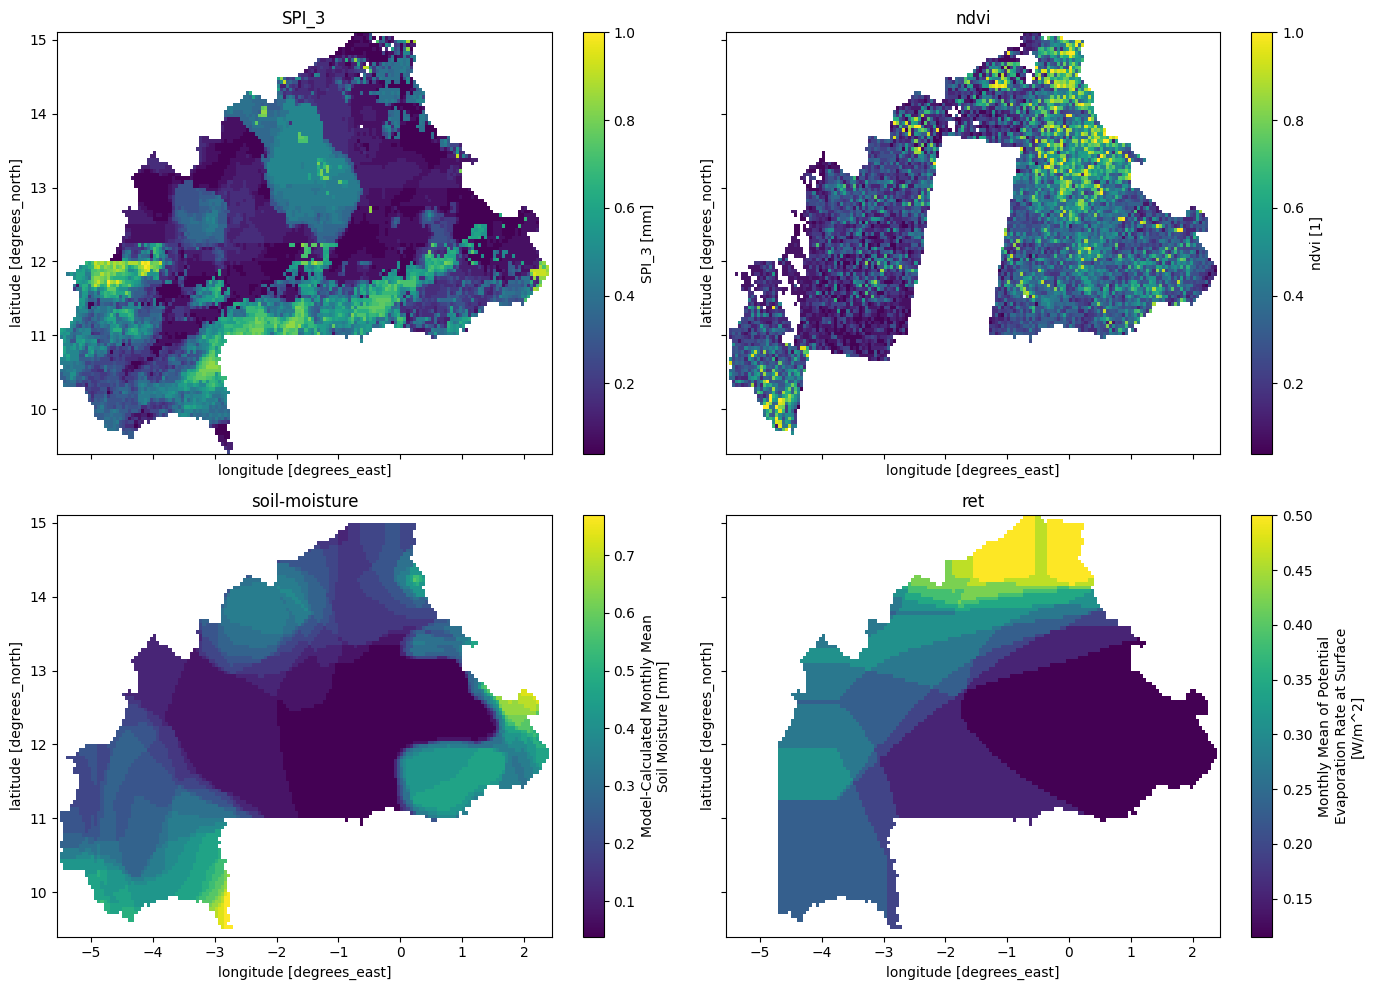

In [46]:
# 1. Create a 2x2 subplot layout
ds_pct_slice = ds_percentiles.isel(time=25)

# 2. Set up a 2x2 grid of subplots
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10), sharex=True, sharey=True)
axes_flat = axes.flatten()

# 3. Loop over the four data variables and plot each
for i, var_name in enumerate(ds_pct_slice.data_vars):
    if i < 4:  # Safety boundary for 4 variables
        ds_pct_slice[var_name].plot(ax=axes_flat[i])
        axes_flat[i].set_title(var_name)

# 4. Clean up alignment and render
plt.tight_layout()
plt.show()

### Run percentile checks

In [32]:
# Select a single month (e.g., all Januaries) for one variable across all years
jan_raw = ds_comb['SPI_3'].sel(time=ds_comb.time.dt.month == 1)
jan_pct = ds_percentiles['SPI_3'].sel(time=ds_percentiles.time.dt.month == 1)

# Grab two specific spatial points
pixel_1_raw = jan_raw.isel(latitude=50, longitude=50)
pixel_1_pct = jan_pct.isel(latitude=50, longitude=50)

pixel_2_raw = jan_raw.isel(latitude=40, longitude=40)
pixel_2_pct = jan_pct.isel(latitude=40, longitude=40)

# The highest raw value at Pixel 1 across all Januaries MUST correspond to 1.0 (or 100%) at Pixel 1
print("Pixel 1 Max Raw Year Index:", pixel_1_raw.argmax(dim="time").values)
print("Pixel 1 Max Percentile Value:", pixel_1_pct.max(dim="time").values) # Should be 1.0

print("Pixel 2 Max Raw Year Index:", pixel_2_raw.argmax(dim="time").values)
print("Pixel 2 Max Percentile Value:", pixel_2_pct.max(dim="time").values) # Should be 1.0

Pixel 1 Max Raw Year Index: 24
Pixel 1 Max Percentile Value: 1.0
Pixel 2 Max Raw Year Index: 24
Pixel 2 Max Percentile Value: 1.0


In [33]:
# Pick a single spatial point (lat, lon) and a single month (e.g., month 5 / May)
lat_idx, lon_idx = 50, 50
month_num = 5

# Extract raw and ranked time-series for May at this point
raw_series = ds_comb['soil-moisture'].sel(time=ds_comb.time.dt.month == month_num).isel(latitude=lat_idx, longitude=lon_idx).to_pandas()
pct_series = ds_percentiles['soil-moisture'].sel(time=ds_percentiles.time.dt.month == month_num).isel(latitude=lat_idx, longitude=lon_idx).to_pandas()

# Create a validation DataFrame
df_check = pd.DataFrame({"Raw_Value": raw_series, "Percentile_Rank": pct_series})

# Sort by raw value
df_check_sorted = df_check.sort_values(by="Raw_Value")

print(f"--- Verification for Month {month_num} at Pixel ({lat_idx}, {lon_idx}) ---")
print(df_check_sorted)

# Assertion test: Is the Percentile Rank monotonically increasing when sorted by Raw_Value?
assert df_check_sorted['Percentile_Rank'].is_monotonic_increasing, "FAILED: Ranks are not properly ordered by month!"
print("\n✅ PASSED: Ranks correctly correspond to month-grouped order!")

--- Verification for Month 5 at Pixel (50, 50) ---
             Raw_Value  Percentile_Rank
time                                   
2002-05-01   65.976898         0.038462
2015-05-01   74.262993         0.076923
2008-05-01   74.611778         0.115385
2006-05-01   77.888420         0.153846
2005-05-01   82.835754         0.192308
2025-05-01   94.633011         0.230769
2018-05-01   96.265579         0.269231
2009-05-01   97.079437         0.307692
2020-05-01   97.469208         0.346154
2010-05-01   98.423149         0.384615
2023-05-01  103.033073         0.423077
2011-05-01  103.076439         0.461538
2003-05-01  104.968918         0.500000
2024-05-01  105.617294         0.538462
2021-05-01  107.030144         0.576923
2001-05-01  108.792290         0.615385
2013-05-01  113.774284         0.653846
2000-05-01  114.085999         0.692308
2022-05-01  114.460892         0.730769
2017-05-01  118.376549         0.769231
2004-05-01  121.933029         0.807692
2012-05-01  121.980476       

# Conduct Principal Component Analysis (PCA)

In [34]:
var_names = ["ndvi", "SPI_3", "soil-moisture", "ret"]
monthly_weights = {}

# Loop through each month (1 to 12)
for m in range(1, 13):
  # Subset baseline data to the specific month
  ds_m = ds_percentiles.sel(time=ds_percentiles["time.month"] == m)

  # Flatten time, lat, lon into a 2D table
  df_list = [ds_m[var].values.flatten() for var in var_names]
  df_data = pd.DataFrame(dict(zip(var_names, df_list))).dropna()

  # Compute 4x4 Correlation Matrix for this month
  corr_matrix = df_data.corr().values

  # Compute Eigenvalues and Eigenvectors
  evals, evecs = np.linalg.eig(corr_matrix)
  v1 = evecs[:, np.argmax(evals)]

  # Normalize unit vector and square for weights
  v1 = v1 / np.linalg.norm(v1)
  w = (v1**2) / np.sum(v1**2)

  monthly_weights[m] = dict(zip(var_names, w))

# Print weights for comparison  (e.g., January vs. August)
print("January Weights:", monthly_weights[1])
print("August Weights:", monthly_weights[8])

January Weights: {'ndvi': np.float64(0.43515462707848684), 'SPI_3': np.float64(0.006648057075075187), 'soil-moisture': np.float64(0.22489870856645952), 'ret': np.float64(0.3332986072799784)}
August Weights: {'ndvi': np.float64(0.0005325956515884439), 'SPI_3': np.float64(0.31869265641052735), 'soil-moisture': np.float64(0.3765081921754946), 'ret': np.float64(0.3042665557623896)}


In [35]:
# 1. Convert nested dictionary to DataFrame
df_weights = pd.DataFrame.from_dict(monthly_weights, orient="index")

# 2. Add clean row and column naming
df_weights.index.name = "Month"

# Optional: Map numeric month numbers to month names
month_names = {
    1: "Jan",
    2: "Feb",
    3: "Mar",
    4: "Apr",
    5: "May",
    6: "Jun",
    7: "Jul",
    8: "Aug",
    9: "Sep",
    10: "Oct",
    11: "Nov",
    12: "Dec",
}
df_weights.index = df_weights.index.map(month_names)

# 3. Export to CSV
df_weights.to_csv("data/monthly_pca_weights.csv")

# Display the formatted table
df_weights

,ndvi,SPI_3,soil-moisture,ret
Month,,,,
Jan,0.435155,0.006648,0.224899,0.333299
Feb,0.314673,0.256070,0.186073,0.243184
Mar,0.289701,0.253594,0.191813,0.264892
Apr,0.181084,0.309320,0.297821,0.211775
May,0.117789,0.341012,0.325954,0.215244
Jun,0.171665,0.287420,0.326910,0.214005
Jul,0.038907,0.301713,0.351490,0.307889
Aug,0.000533,0.318693,0.376508,0.304267
Sep,0.055752,0.260367,0.369149,0.314733


## Assess PCA Weight stablity with bootstrapping

In [36]:
bootstrapped_monthly_weights = defaultdict(list)
all_years = np.unique(ds_percentiles['time.year'].values)

print(f"Performing leave-one-year-out bootstrapping across years: {all_years}")

for year_to_exclude in tqdm(all_years, desc="Bootstrapping years"):
    # Create a subset of the dataset, excluding the current year
    ds_subset = ds_percentiles.sel(time=ds_percentiles['time.year'] != year_to_exclude)

    # Calculate monthly PCA weights for this subset
    for m in range(1, 13):
        # Subset to the specific month within the current subset
        ds_m_subset = ds_subset.sel(time=ds_subset["time.month"] == m)

        # Flatten time, lat, lon into a 2D table
        df_list_subset = [ds_m_subset[var].values.flatten() for var in var_names]
        df_data_subset = pd.DataFrame(dict(zip(var_names, df_list_subset))).dropna()

        current_month_weights_dict = {'excluded_year': year_to_exclude} # Always include excluded_year
        for var in var_names:
            current_month_weights_dict[var] = np.nan # Initialize weights to NaN

        # Ensure enough data points for correlation calculation (at least N+1 samples for N variables)
        if df_data_subset.shape[0] >= len(var_names) + 1:
            # Compute 4x4 Correlation Matrix for this month
            corr_matrix_subset = df_data_subset.corr().values

            # Handle cases where correlation matrix might have NaNs (e.g., if a variable has no variance)
            if not np.isnan(corr_matrix_subset).any():
                try:
                    # Compute Eigenvalues and Eigenvectors
                    evals_subset, evecs_subset = np.linalg.eig(corr_matrix_subset)

                    # Ensure we have valid eigenvalues/vectors
                    if np.isreal(evals_subset).all(): # Check if eigenvalues are real
                        v1_subset = evecs_subset[:, np.argmax(evals_subset)]

                        # Normalize unit vector and square for weights
                        v1_subset = v1_subset / np.linalg.norm(v1_subset)
                        w_subset = (v1_subset**2) / np.sum(v1_subset**2)

                        # Update weights for the current month with calculated values
                        for var_idx, var_name in enumerate(var_names):
                            current_month_weights_dict[var_name] = w_subset[var_idx]
                except Exception:
                    # If PCA calculation fails for any other reason, keep weights as NaN
                    pass

        # Store the dictionary for the current month and excluded year
        bootstrapped_monthly_weights[m].append(current_month_weights_dict)

# Convert results to a DataFrame for easier analysis
bootstrapped_weights_df = pd.DataFrame(
    [
        ("Month " + str(m), month_data['excluded_year'], var, w)
        for m, month_data_list in bootstrapped_monthly_weights.items()
        for month_data in month_data_list # Each month_data is now a dict like {'excluded_year': Y, 'ndvi': W1, 'SPI_3': W2, ...}
        for var, w in month_data.items()
        if var in var_names # Filter out 'excluded_year' when iterating over items to get var, w
    ],
    columns=['Month', 'Excluded_Year', 'Variable', 'Weight']
)

display(bootstrapped_weights_df.head())


Performing leave-one-year-out bootstrapping across years: [2000 2001 2002 2003 2004 2005 2006 2007 2008 2009 2010 2011 2012 2013
 2014 2015 2016 2017 2018 2019 2020 2021 2022 2023 2024 2025]


Bootstrapping years:   0%|          | 0/26 [00:00<?, ?it/s]

,Month,Excluded_Year,Variable,Weight
0,Month 1,2000,ndvi,0.435155
1,Month 1,2000,SPI_3,0.006648
2,Month 1,2000,soil-moisture,0.224899
3,Month 1,2000,ret,0.333299
4,Month 1,2001,ndvi,0.433614


This plot shows the original PCA weights (black dots) and the distribution of weights when one year is removed from the dataset (blue box plots and individual dots). If the blue distributions are tightly clustered around the black dots, it indicates good stability. Wide distributions or significant shifts would suggest that the specific years removed have a substantial impact, and potentially more data could be beneficial for a more robust PCA model.

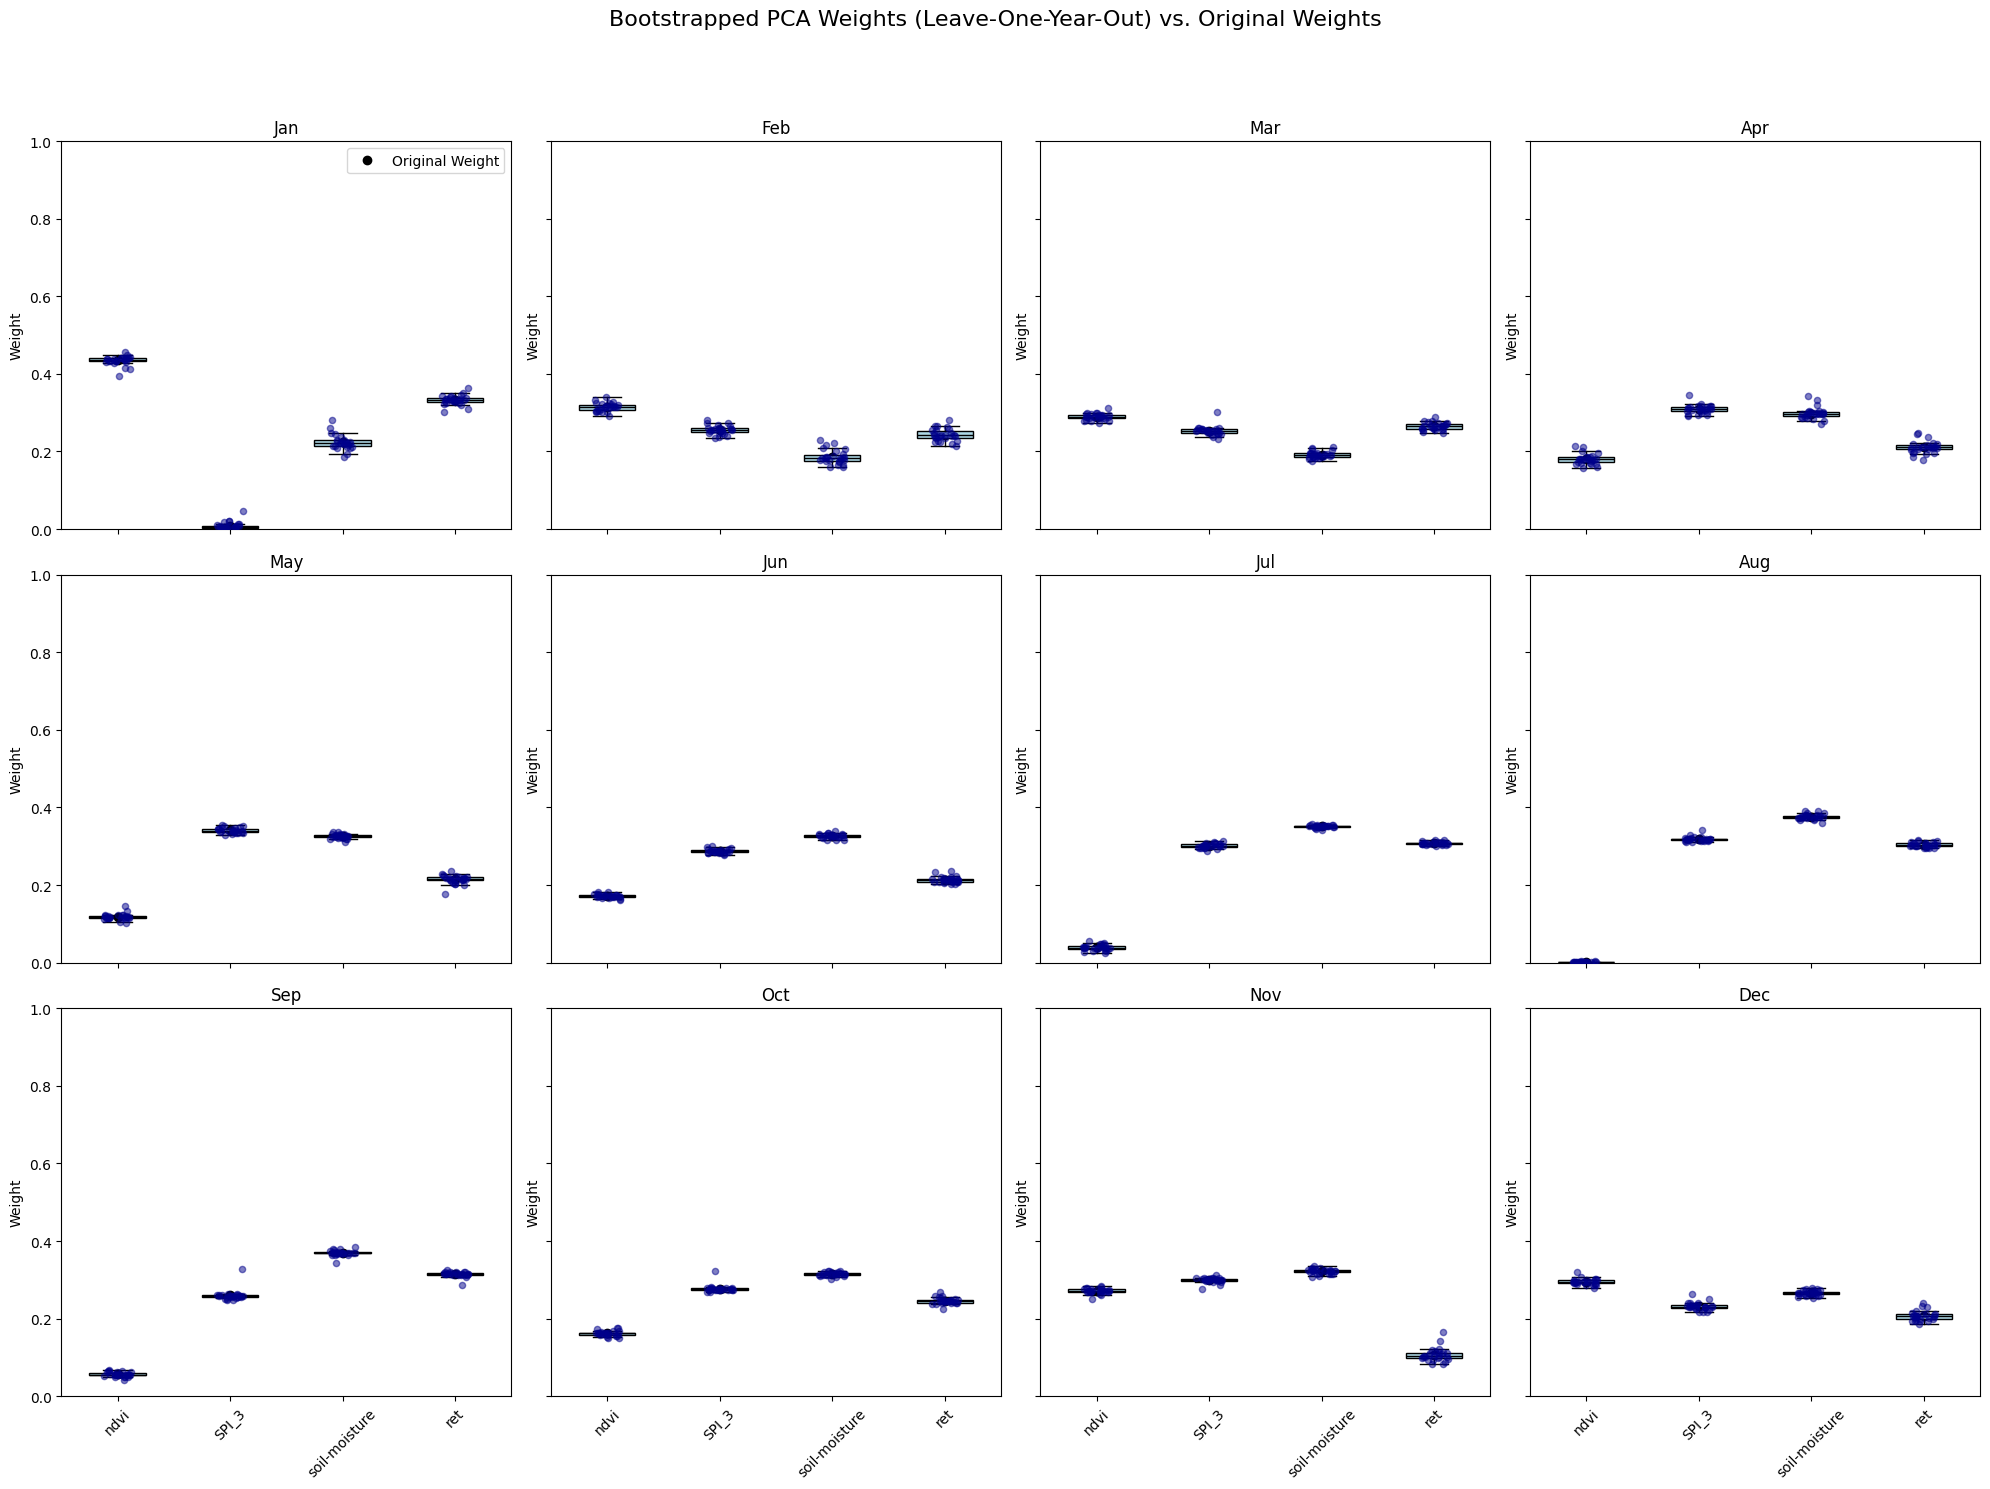

In [37]:
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(20, 15), sharex=True, sharey=True)
axes_flat = axes.flatten()

rng = np.random.default_rng(42)  # Reproducible jitter for the strip plot points

for i, m_num in enumerate(range(1, 13)):
    ax = axes_flat[i]
    month_name = month_names[m_num]

    # Get original weights for the current month (ordered to match var_names)
    original_weights_month = df_weights.loc[month_name, var_names]
    x_positions = np.arange(len(var_names))

    # Plot original weights as points (zorder=1 to be behind)
    ax.plot(
        x_positions,
        original_weights_month.values,
        'o',
        color='black',
        label='Original Weight',
        zorder=1,
    )

    # Get bootstrapped weights for the current month
    boot_weights_month_data = bootstrapped_monthly_weights[m_num]

    if boot_weights_month_data:
        temp_df = pd.DataFrame(boot_weights_month_data)[var_names]

        if not temp_df.isnull().all().all():
            # Extract non-NaN arrays per variable for matplotlib's boxplot
            box_data = [temp_df[var].dropna().values for var in var_names]

            # Equivalent to sns.boxplot(..., width=0.5, showfliers=False, color='lightblue')
            ax.boxplot(
                box_data,
                positions=x_positions,
                widths=0.5,
                showfliers=False,
                patch_artist=True,
                boxprops=dict(facecolor='lightblue', edgecolor='black'),
                medianprops=dict(color='black'),
                whiskerprops=dict(color='black'),
                capprops=dict(color='black'),
                zorder=2,
            )

            # Equivalent to sns.stripplot(..., jitter=True, color='darkblue', alpha=0.5)
            for pos, values in zip(x_positions, box_data):
                jitter = rng.uniform(-0.12, 0.12, size=len(values))
                ax.scatter(
                    np.repeat(pos, len(values)) + jitter,
                    values,
                    color='darkblue',
                    alpha=0.5,
                    s=20,
                    zorder=3,
                )
        else:
            print(f"Month {month_name}: No valid bootstrapped weights to plot.")
    else:
        print(f"Month {month_name}: No valid bootstrapped weights to plot.")

    ax.set_xticks(x_positions)
    ax.set_xticklabels(var_names)
    ax.set_title(f'{month_name}')
    ax.set_ylim(0, 1)
    ax.set_ylabel('Weight')
    ax.tick_params(axis='x', rotation=45)
    ax.set_xlabel('')

    if i == 0:  # Add legend only to the first plot
        ax.legend()

plt.suptitle('Bootstrapped PCA Weights (Leave-One-Year-Out) vs. Original Weights', fontsize=16, y=1.02)
plt.tight_layout(rect=[0, 0.03, 1, 0.98])
plt.show()

## Calculate Coefficient of Variation (CV) for PCA Weight Stability

In [38]:
cv_data = defaultdict(dict)

for m_num in range(1, 13):
    month_name = month_names[m_num]
    boot_weights_month_data = bootstrapped_monthly_weights[m_num]

    if boot_weights_month_data:
        temp_df = pd.DataFrame(boot_weights_month_data)
        # Select only the actual variable columns
        boot_df_month = temp_df[var_names]

        for var in var_names:
            # Calculate CV, ignoring NaNs
            mean_weight = boot_df_month[var].mean()
            std_weight = boot_df_month[var].std()

            if mean_weight != 0 and not pd.isna(mean_weight):
                cv = (std_weight / mean_weight)
            else:
                cv = np.nan # If mean is zero or NaN, CV is not meaningful
            cv_data[month_name][var] = cv
    else:
        for var in var_names:
            cv_data[month_name][var] = np.nan

df_cv_weights = pd.DataFrame.from_dict(cv_data, orient='index')
df_cv_weights.index.name = 'Month'

print("Coefficient of Variation for Bootstrapped PCA Weights:")
display(df_cv_weights)

Coefficient of Variation for Bootstrapped PCA Weights:


,ndvi,SPI_3,soil-moisture,ret
Month,,,,
Jan,0.027107,1.126707,0.085762,0.036359
Feb,0.033745,0.042395,0.097344,0.064615
Mar,0.028321,0.047218,0.045734,0.035142
Apr,0.075694,0.035638,0.050278,0.074536
May,0.066718,0.019217,0.017807,0.051140
Jun,0.028091,0.018250,0.015831,0.036816
Jul,0.177639,0.019318,0.009520,0.012205
Aug,1.120088,0.020312,0.017919,0.018800
Sep,0.105212,0.056484,0.018882,0.021422


In [39]:
overall_average_cv = df_cv_weights.mean().mean()
print(f"Overall Average Coefficient of Variation: {overall_average_cv:.4f}")

Overall Average Coefficient of Variation: 0.0888


## Temporal patterns in weights

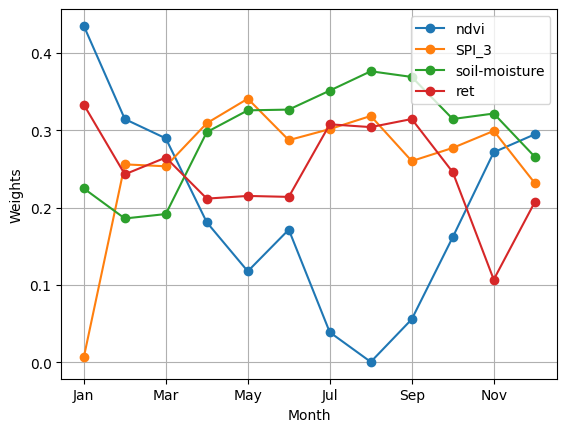

In [40]:
df_weights.plot(y=['ndvi', 'SPI_3', 'soil-moisture', 'ret'], kind='line', marker='o')

plt.ylabel('Weights')
plt.grid(True)

plt.show()

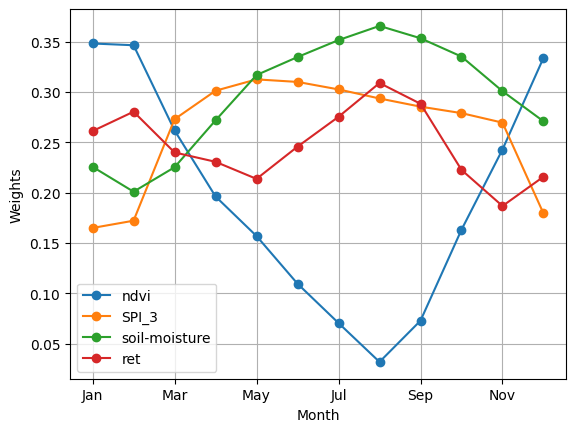

In [41]:
# Pad December before Jan and January after Dec for seamless cyclic smoothing
weights_padded = pd.concat(
    [df_weights.iloc[-1:], df_weights, df_weights.iloc[:1]]
)

# Apply 3-month centered moving average
smoothed = weights_padded.rolling(window=3, center=True).mean().iloc[1:-1]

# Re-normalize each month row to sum strictly to 1.0
final_weights = smoothed.div(smoothed.sum(axis=1), axis=0)

final_weights.plot(y=['ndvi', 'SPI_3', 'soil-moisture', 'ret'], kind='line', marker='o')

plt.ylabel('Weights')
plt.grid(True)

plt.show()

## Weights per cell

In [45]:
ds_percentiles

<xarray.Dataset> Size: 182MB
Dimensions:        (latitude: 114, longitude: 160, time: 312)
Coordinates:
  * latitude       (latitude) float64 912B 15.08 15.03 14.98 ... 9.475 9.425
  * longitude      (longitude) float64 1kB -5.525 -5.475 -5.425 ... 2.375 2.425
  * time           (time) datetime64[ns] 2kB 2000-01-01 ... 2025-12-01
    spatial_ref    int32 4B 4326
Data variables:
    SPI_3          (time, latitude, longitude) float64 46MB nan nan ... nan nan
    ndvi           (time, latitude, longitude) float64 46MB nan nan ... nan nan
    soil-moisture  (time, latitude, longitude) float64 46MB nan nan ... nan nan
    ret            (time, latitude, longitude) float64 46MB nan nan ... nan nan

In [47]:
n_lat = ds_percentiles.sizes["latitude"]
n_lon = ds_percentiles.sizes["longitude"]

# Pre-allocate output arrays: (month: 12, latitude, longitude)
w_out = {
    v: np.full((12, n_lat, n_lon), np.nan, dtype=float) for v in var_names
}

for m in range(1, 13):
    # Subset to calendar month m -> shape: (time_m, latitude, longitude)
    ds_m = ds_percentiles.sel(time=ds_percentiles["time.month"] == m)
    arrs = [ds_m[v].values for v in var_names]

    for i in range(n_lat):
        for j in range(n_lon):
            # Extract (T, 4) matrix for cell (i, j) and drop rows where any variable is NaN
            cell_data = np.column_stack([a[:, i, j] for a in arrs])
            cell_clean = cell_data[~np.isnan(cell_data).any(axis=1)]

            # Need at least 3 valid years and non-zero variance in all 4 variables
            if cell_clean.shape[0] < 3 or np.any(
                np.std(cell_clean, axis=0) == 0
            ):
                continue

            # Compute 4x4 Correlation Matrix (matches df_data.corr())
            corr_matrix = np.corrcoef(cell_clean, rowvar=False)
            if np.isnan(corr_matrix).any():
                continue

            # Eigenvalues and Eigenvectors (matches your original formula)
            evals, evecs = np.linalg.eigh(corr_matrix)
            v1 = evecs[:, -1]

            v1 = v1 / np.linalg.norm(v1)
            w = (v1**2) / np.sum(v1**2)

            for idx, v in enumerate(var_names):
                w_out[v][m - 1, i, j] = w[idx]

# Package into an xr.Dataset with dims (month, latitude, longitude)
ds_monthly_weights = xr.Dataset(
    {
        v: (("month", "latitude", "longitude"), w_out[v])
        for v in var_names
    },
    coords={
        "month": np.arange(1, 13),
        "latitude": ds_percentiles["latitude"],
        "longitude": ds_percentiles["longitude"],
    },
)

print(
    "Valid cells in Jan:",
    int(ds_monthly_weights["ndvi"].sel(month=1).notnull().sum()),
)

Valid cells in Jan: 8561


In [51]:
ds_monthly_weights

<xarray.Dataset> Size: 7MB
Dimensions:        (month: 12, latitude: 114, longitude: 160)
Coordinates:
  * month          (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
  * latitude       (latitude) float64 912B 15.08 15.03 14.98 ... 9.475 9.425
  * longitude      (longitude) float64 1kB -5.525 -5.475 -5.425 ... 2.375 2.425
    spatial_ref    int32 4B 4326
Data variables:
    ndvi           (month, latitude, longitude) float64 2MB nan nan ... nan nan
    SPI_3          (month, latitude, longitude) float64 2MB nan nan ... nan nan
    soil-moisture  (month, latitude, longitude) float64 2MB nan nan ... nan nan
    ret            (month, latitude, longitude) float64 2MB nan nan ... nan nan

### Check cell weights sum to 1

In [52]:
# Sum across the 4 variables at every (month, latitude, longitude)
weight_sum = (
    ds_monthly_weights["ndvi"]
    + ds_monthly_weights["SPI_3"]
    + ds_monthly_weights["soil-moisture"]
    + ds_monthly_weights["ret"]
)

# Check only non-NaN (land) cells
valid_sums = weight_sum.values[~np.isnan(weight_sum.values)]

print("Min sum:", valid_sums.min())
print("Max sum:", valid_sums.max())
print("All valid cells sum to 1.0:", np.allclose(valid_sums, 1.0))

Min sum: 0.9999999999999997
Max sum: 1.0000000000000002
All valid cells sum to 1.0: True


## Plot weights through time

Ribbons represent spatial variability.

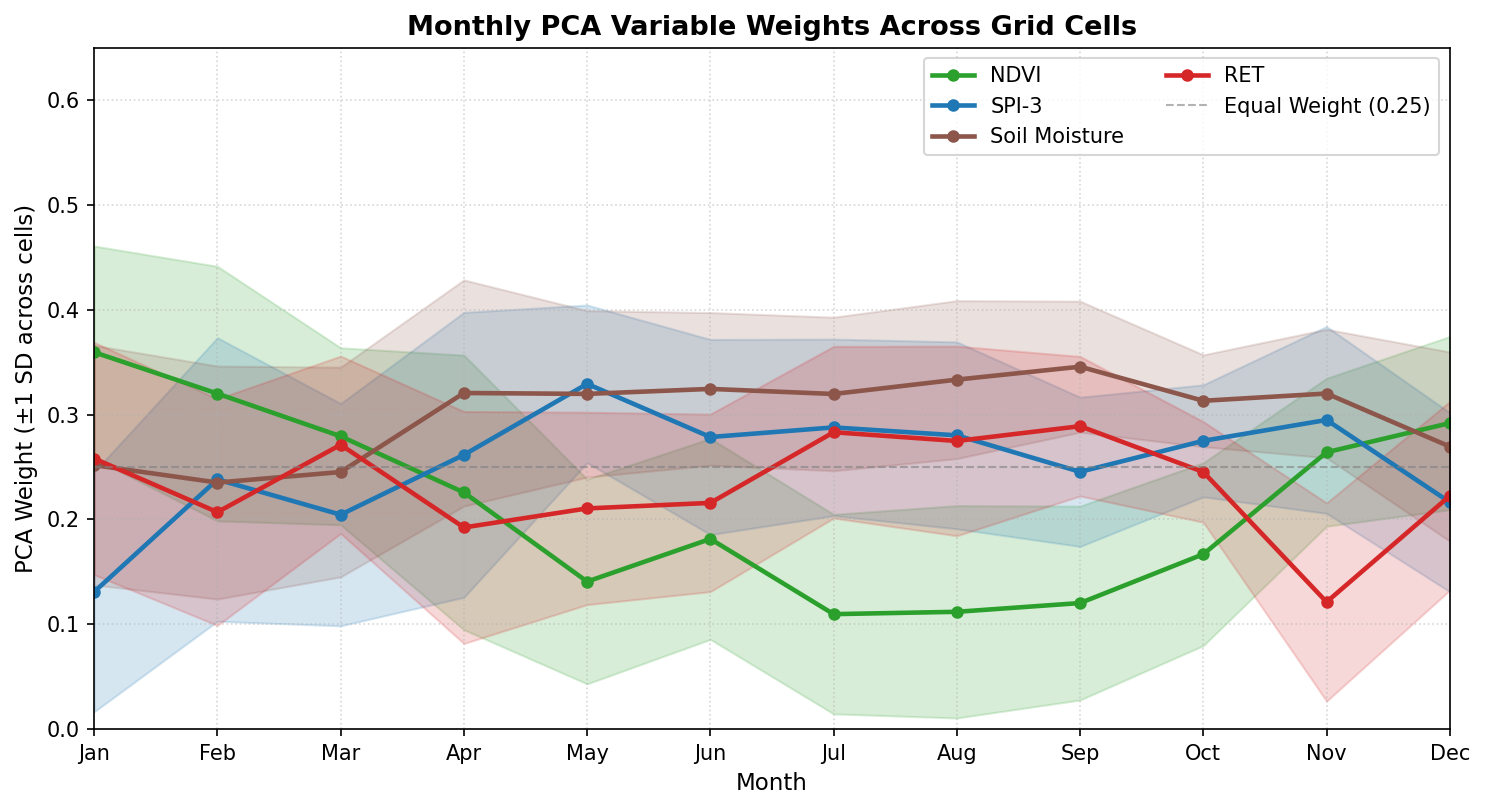

In [54]:
ds_plot = ds_monthly_weights

var_names = ["ndvi", "SPI_3", "soil-moisture", "ret"]
labels = {
    "ndvi": "NDVI",
    "SPI_3": "SPI-3",
    "soil-moisture": "Soil Moisture",
    "ret": "RET",
}
colors = {
    "ndvi": "#2ca02c",          # Green
    "SPI_3": "#1f77b4",         # Blue
    "soil-moisture": "#8c564b", # Brown
    "ret": "#d62728",           # Red
}

months = ds_plot["month"].values
month_names = [calendar.month_abbr[m] for m in months]

fig, ax = plt.subplots(figsize=(10, 5.5), dpi=150)

for v in var_names:
    # Spatial mean and standard deviation across all valid land cells
    mean_w = ds_plot[v].mean(dim=["latitude", "longitude"], skipna=True).values
    std_w = ds_plot[v].std(dim=["latitude", "longitude"], skipna=True).values

    # Clip ribbon bounds to [0, 1] since weights cannot be negative or > 1
    lower = np.clip(mean_w - std_w, 0.0, 1.0)
    upper = np.clip(mean_w + std_w, 0.0, 1.0)

    ax.plot(
        months,
        mean_w,
        label=labels[v],
        color=colors[v],
        linewidth=2.2,
        marker="o",
        markersize=5,
    )
    ax.fill_between(
        months,
        lower,
        upper,
        color=colors[v],
        alpha=0.18,
    )

# Equal-weight reference line (0.25)
ax.axhline(0.25, color="gray", linestyle="--", linewidth=1, alpha=0.6, label="Equal Weight (0.25)")

ax.set_xticks(months)
ax.set_xticklabels(month_names)
ax.set_xlim(1, 12)
ax.set_ylim(0, 0.65)  # Adjust upper limit if any weight peak exceeds 0.65
ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("PCA Weight (±1 SD across cells)", fontsize=11)
ax.set_title("Monthly PCA Variable Weights Across Grid Cells", fontsize=13, fontweight="bold")
ax.grid(True, linestyle=":", alpha=0.5)
ax.legend(frameon=True, ncol=2, fontsize=10)

plt.tight_layout()
plt.show()

## Create spatial plot of weights

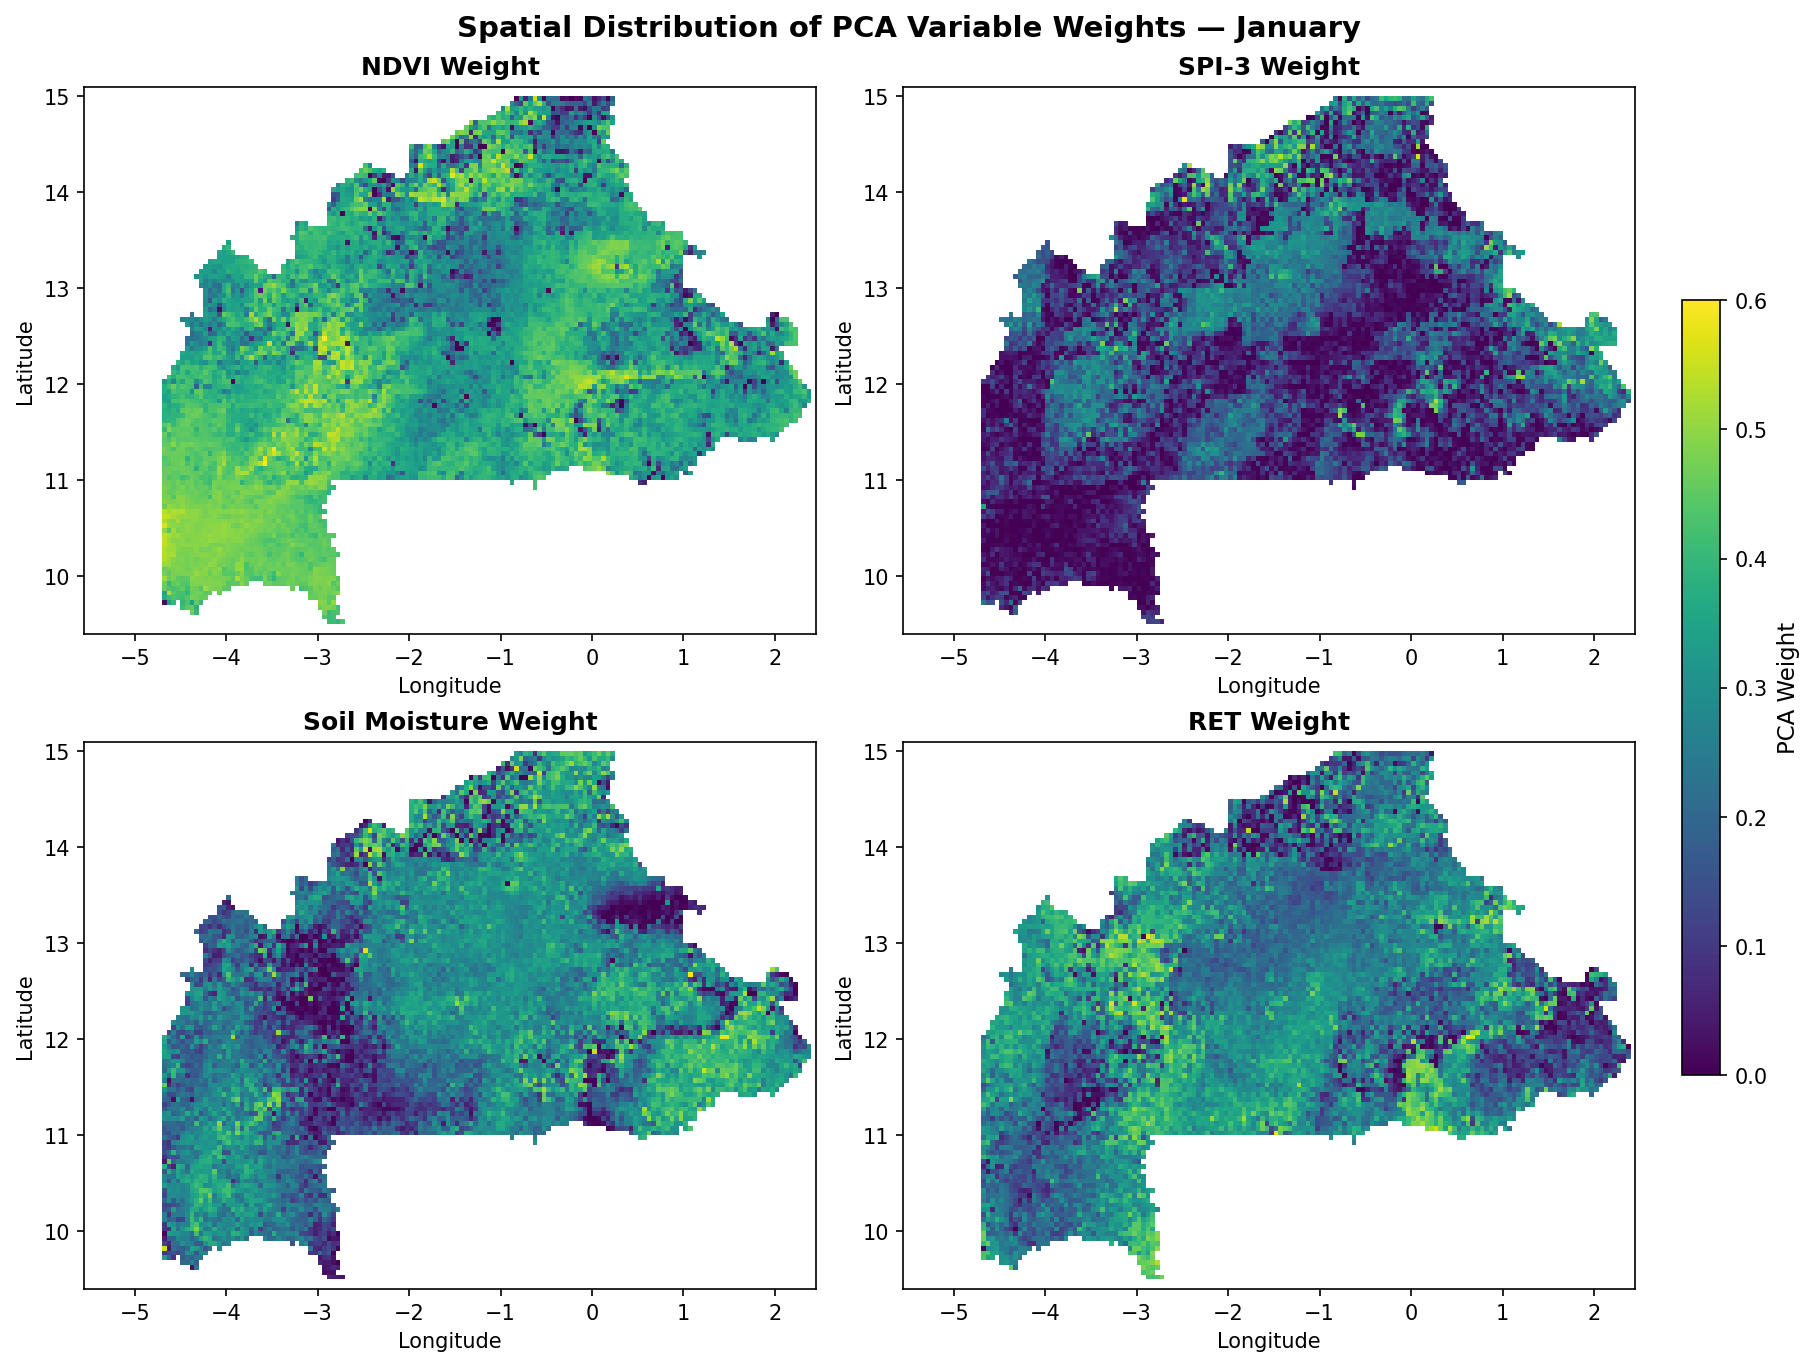

In [55]:
# Select the month you want to inspect (1 = Jan, ..., 8 = Aug)
selected_month = 1

var_names = ["ndvi", "SPI_3", "soil-moisture", "ret"]
titles = {
    "ndvi": "NDVI Weight",
    "SPI_3": "SPI-3 Weight",
    "soil-moisture": "Soil Moisture Weight",
    "ret": "RET Weight",
}

ds_m = ds_monthly_weights.sel(month=selected_month)

fig, axes = plt.subplots(2, 2, figsize=(12, 9), dpi=150, constrained_layout=True)

for ax, v in zip(axes.flat, var_names):
    im = ds_m[v].plot(
        ax=ax,
        cmap="viridis",
        vmin=0.0,
        vmax=0.6,  # Adjust if individual cell weights peak higher
        add_colorbar=False,
    )
    ax.set_title(titles[v], fontsize=12, fontweight="bold")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

# Single shared colorbar across all 4 subplots
cbar = fig.colorbar(im, ax=axes, orientation="vertical", fraction=0.025, pad=0.03)
cbar.set_label("PCA Weight", fontsize=11)

month_name = calendar.month_name[selected_month]
fig.suptitle(
    f"Spatial Distribution of PCA Variable Weights — {month_name}",
    fontsize=14,
    fontweight="bold",
)

plt.show()

***

## Additional information

**License:** The code in this notebook is licensed under the [Apache License, Version 2.0](https://www.apache.org/licenses/LICENSE-2.0). 
Digital Earth Africa data is licensed under the [Creative Commons by Attribution 4.0](https://creativecommons.org/licenses/by/4.0/) license.

**Contact:** If you need assistance, please post a question on the [Open Data Cube Slack channel](http://slack.opendatacube.org/) or on the [GIS Stack Exchange](https://gis.stackexchange.com/questions/ask?tags=open-data-cube) using the `open-data-cube` tag (you can view previously asked questions [here](https://gis.stackexchange.com/questions/tagged/open-data-cube)).
If you would like to report an issue with this notebook, you can file one on [Github](https://github.com/digitalearthafrica/deafrica-sandbox-notebooks).

**Compatible datacube version:** 

In [ ]:
print(datacube.__version__)

**Last Tested:**

In [ ]:
from datetime import datetime
datetime.today().strftime('%Y-%m-%d')